<a href="https://colab.research.google.com/github/Rohit-Aroonslam/HCIA_Course/blob/main/HCIA_ML_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.2.1 Linear Regression

## Step 1: Import dependent packages

In [12]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import numpy as np

## Step 2: Build and visualize a house price dataset
Plot house area against price to see the relationship in the data.

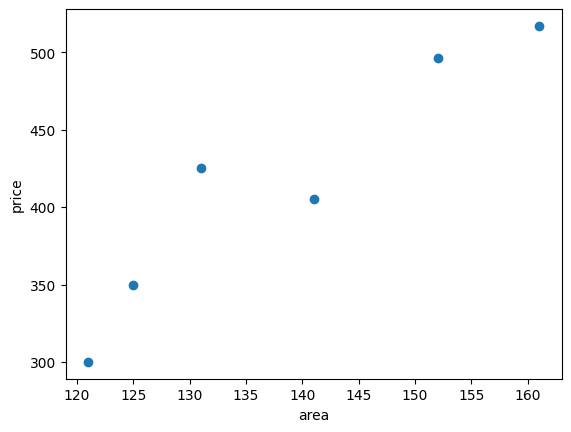

In [13]:

x = np.array([121, 125, 131, 141, 152, 161]).reshape(-1,1)
y = np.array([300, 350, 425, 405, 496, 517])
plt.scatter(x,y)
plt.xlabel("area")
plt.ylabel("price")
plt.show()

## Step 3: Train the model
Create a linear regression model and fit it to the area and price data.

In [14]:
lr = LinearRegression()
lr.fit(x,y)

LinearRegression()

## Step 4: Model parameters
Print the slope and intercept of the line the model found.

In [15]:
w = lr.coef_
b = lr.intercept_
print('Slope: ',w)
print('Intercept: ',b)

Slope:  [4.98467124]
Intercept:  -274.8769665187576


## Step 4 (continued): Visualize the fitted model
Plot the fitted regression line over the data points.

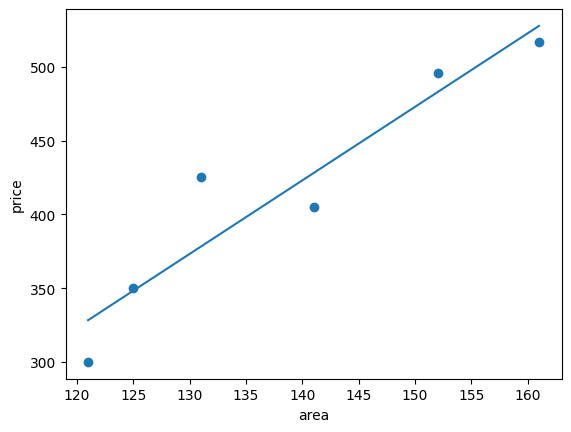

In [16]:
plt.scatter(x,y)
plt.xlabel("area")
plt.ylabel("price")
plt.plot([x[0],x[-1]],[x[0]*w+b,x[-1]*w+b])
plt.show()

## Step 5: Predict a house price
Use the trained model to predict the price of a house with an area of 130.

In [17]:
testX = np.array([[130]])
lr.predict(testX)

array([373.13029447])

# 1.2.2 Linear Regression Implementation (Expansion Experiment)

## Step 1: Import dependencies

In [24]:
import numpy as np
import matplotlib.pyplot as plt

In [18]:
!unzip -q Dataset.zip
!find . -name "lr2_data.txt"

replace TextCNN/data/rt-polarity.neg? [y]es, [n]o, [A]ll, [N]one, [r]ename: ./ML/02/lr2_data.txt


## Step 2: Define the gradient function
Calculate the gradient of the loss with respect to theta, averaged over all samples.

In [25]:
def generate_gradient(X, theta, y):
    sample_count = X.shape[0]
    return (1./sample_count)*X.T.dot(X.dot(theta)-y)

## Step 3: Define the data-reading function
Load the dataset and split it into features and the target value.

In [26]:
def get_training_data(file_path):
    orig_data = np.loadtxt(file_path, skiprows=1)
    cols = orig_data.shape[1]
    return (orig_data, orig_data[:, :cols - 1], orig_data[:, cols-1:])

## Step 4: Define the parameter initialization function
Start theta as an array of ones, one value per feature.

In [19]:
def init_theta(feature_count):
    return np.ones(feature_count).reshape(feature_count, 1)

## Step 5: Define the gradient descent function
Repeatedly update theta in the opposite direction of the gradient until the gradient is almost zero, recording the loss as we go.

In [20]:
def gradient_descending(X, y, theta, alpha):
    Jthetas = []
    Jtheta = (X.dot(theta)-y).T.dot(X.dot(theta)-y)
    index = 0
    gradient = generate_gradient(X, theta, y)
    while not np.all(np.absolute(gradient) <= 1e-5):
        theta = theta - alpha * gradient
        gradient = generate_gradient(X, theta, y)
        Jtheta = (X.dot(theta)-y).T.dot(X.dot(theta)-y)
        if (index+1) % 10 == 0:
            Jthetas.append((index, Jtheta[0]))
        index += 1
    return theta, Jthetas

## Step 6: Define the loss curve function
Plot how the loss changes over the gradient descent steps, to confirm it is decreasing.

In [21]:
def showJTheta(diff_value):
    p_x = []
    p_y = []
    for (index, sum) in diff_value:
        p_x.append(index)
        p_y.append(sum)
    plt.plot(p_x, p_y, color='b')
    plt.xlabel('steps')
    plt.ylabel('loss function')
    plt.title('step - loss function curve')
    plt.show()

## Step 7: Define the fitted curve function
Plot the actual data points and the regression line the model learned.

In [22]:
def showlinercurve(theta, sample_training_set):
    x, y = sample_training_set[:, 1], sample_training_set[:, 2]
    z = theta[0] + theta[1] * x
    plt.scatter(x, y, color='b', marker='x', label="sample data")
    plt.plot(x, z, color="r", label="regression curve")
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('liner regression curve')
    plt.legend()
    plt.show()

## Step 8: Train and plot the final results
Load the dataset, run gradient descent, and show the learned parameters, the loss curve and the fitted line.

w:3.0076279423997594 b:1.668677412281192


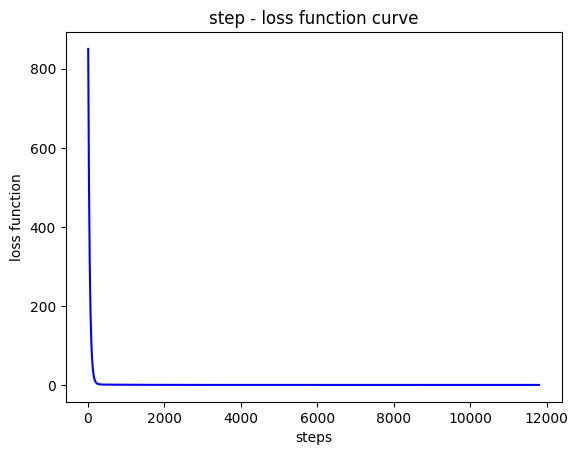

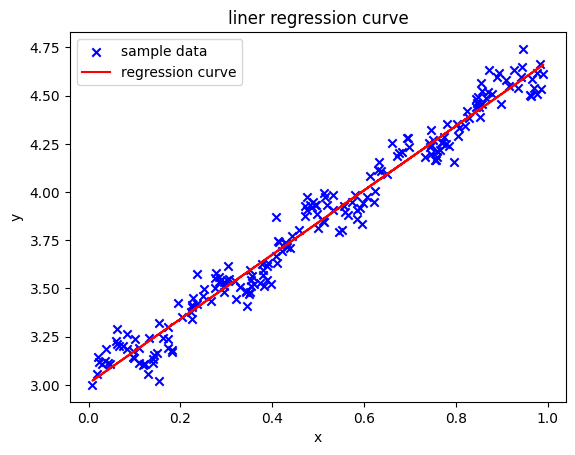

In [27]:
training_data_include_y, training_x, y = get_training_data("./ML/02/lr2_data.txt")
sample_count, feature_count = training_x.shape
alpha = 0.01
theta = init_theta(feature_count)
result_theta, Jthetas = gradient_descending(training_x, y, theta, alpha)
print("w:{}".format(result_theta[0][0]), "b:{}".format(result_theta[1][0]))
showJTheta(Jthetas)
showlinercurve(result_theta, training_data_include_y)

# 1.2.3 Logistic Regression
This experiment uses a custom dataset of house rent and area to classify whether a room is rented.

## Step 1: Import dependencies

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

## Step 2: Define the dataset
X holds the rent and area of each room. y shows whether it was rented (0: no, 1: yes).

In [29]:
X=[[2200,15],[2750,20],[5000,40],[4000,20],[3300,20],[2000,10],[2500,12],[12000,80],
   [2880,10],[2300,15],[1500,10],[3000,8],[2000,14],[2000,10],[2150,8],[3400,20],
   [5000,20],[4000,10],[3300,15],[2000,12],[2500,14],[10000,100],[3150,10],
   [2950,15],[1500,5],[3000,18],[8000,12],[2220,14],[6000,100],[3050,10]
  ]

y=[1,1,0,0,1,1,1,1,0,1,1,0,1,1,0,1,0,0,0,1,1,1,0,1,0,1,0,1,1,0]

## Step 3: Standardize the data
Rescale each feature to mean 0 and variance 1, so large values like rent don't dominate the prediction.

In [30]:
ss = StandardScaler()
X_train = ss.fit_transform(X)
print(X_train)

[[-0.60583897 -0.29313058]
 [-0.37682768 -0.09050576]
 [ 0.56003671  0.71999355]
 [ 0.14365254 -0.09050576]
 [-0.14781638 -0.09050576]
 [-0.68911581 -0.49575541]
 [-0.48092372 -0.41470548]
 [ 3.47472592  2.34099218]
 [-0.32269773 -0.49575541]
 [-0.56420055 -0.29313058]
 [-0.89730789 -0.49575541]
 [-0.27273163 -0.57680534]
 [-0.68911581 -0.33365555]
 [-0.68911581 -0.49575541]
 [-0.62665818 -0.57680534]
 [-0.10617796 -0.09050576]
 [ 0.56003671 -0.09050576]
 [ 0.14365254 -0.49575541]
 [-0.14781638 -0.29313058]
 [-0.68911581 -0.41470548]
 [-0.48092372 -0.33365555]
 [ 2.64195758  3.15149149]
 [-0.21027401 -0.49575541]
 [-0.29355084 -0.29313058]
 [-0.89730789 -0.69838024]
 [-0.27273163 -0.17155569]
 [ 1.80918923 -0.41470548]
 [-0.59751129 -0.33365555]
 [ 0.97642089  3.15149149]
 [-0.25191242 -0.49575541]]


## Step 4: Fit the model
Train the logistic regression model on the standardized data.

In [31]:
lr = LogisticRegression()
lr.fit(X_train, y)

LogisticRegression()

## Step 5: Predict a new sample
Standardize a new room (rent 2000, area 8) with the same scaler, then predict whether it will be rented and with what probability.

In [32]:
testX = [[2000,8]]
X_test = ss.transform(testX)
print("Value to be predicted: ",X_test)
label = lr.predict(X_test)
print("predicted label = ", label)
prob = lr.predict_proba(X_test)
print("probability = ",prob)

Value to be predicted:  [[-0.68911581 -0.57680534]]
predicted label =  [1]
probability =  [[0.41882379 0.58117621]]


# 1.2.4 Decision Tree
This experiment uses the tennis.txt dataset (14 samples of weather features and whether it is suitable for tennis) to build and visualize a decision tree.

## Step 1: Import dependencies

In [33]:
!pip install -q pydotplus
import pandas as pd
import numpy as np
from sklearn import tree
import pydotplus

## Step 2: Define the tree-building function
Train a decision tree classifier using entropy as the split criterion.

In [34]:
def createTree(trainingData):
    data = trainingData.iloc[:, :-1]
    labels = trainingData.iloc[:, -1]
    trainedTree = tree.DecisionTreeClassifier(criterion="entropy")
    trainedTree.fit(data, labels)
    return trainedTree

## Step 3: Define the function that saves the tree as a PDF
Export the trained tree in Graphviz format and write it to a PDF file.

In [35]:
def showtree2pdf(trainedTree, finename):
    dot_data = tree.export_graphviz(trainedTree, out_file=None)
    graph = pydotplus.graph_from_dot_data(dot_data)
    graph.write_pdf(finename)

## Step 4: Define the vectorization function
Convert the text categories (such as sunny or rain) into numbers, because the decision tree only accepts numeric input.

In [36]:
def data2vectoc(data):
    names = data.columns[:-1]
    for i in names:
        col = pd.Categorical(data[i])
        data[i] = col.codes
    return data

## Step 5: Build the tree and plot it
Read the training data, vectorize it, create the decision tree and save the diagram as tennis.pdf.

In [43]:
data = pd.read_table("./ML/tennis.txt", header=None, sep='\t')
trainingvec = data2vectoc(data)
decisionTree = createTree(trainingvec)
showtree2pdf(decisionTree, "tennis.pdf")

## Predict a new sample
Predict whether tennis is suitable when the weather is sunny, temperature is low, humidity is high and wind is strong.

In [44]:
testVec = [0,0,1,1]
print(decisionTree.predict(np.array(testVec).reshape(1,-1)))

['Y']


In [45]:
raw = pd.read_table("./ML/tennis.txt", header=None, sep='\t')
print(raw)
for i in range(4):
    print(i, list(pd.Categorical(raw[i]).categories))

         0         1       2       3  4
0    sunny       hot    high    weak  N
1    sunny       hot    high  strong  N
2   cloudy       hot    high    weak  Y
3     rain  moderate    high    weak  Y
4     rain      cold  normal    weak  Y
5     rain      cold  normal  strong  N
6   cloudy      cold  normal  strong  Y
7    sunny  moderate    high    weak  N
8    sunny      cold  normal    weak  Y
9     rain  moderate  normal    weak  Y
10   sunny  moderate  normal  strong  Y
11  cloudy  moderate    high  strong  Y
12  cloudy       hot  normal    weak  Y
13    rain  moderate    high  strong  N
0 ['cloudy', 'rain', 'sunny']
1 ['cold', 'hot', 'moderate']
2 ['high', 'normal']
3 ['strong', 'weak']


In [46]:
testVec = [2,0,0,0]
print(decisionTree.predict(np.array(testVec).reshape(1,-1)))

['N']


# 1.2.5 K-means Algorithm Implementation
Generate a dataset of points and use K-means clustering to group them.

## Step 1: Import dependencies
make_blobs generates the dataset, matplotlib draws the graphs, and KMeans fits the clusters.

In [47]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

## Step 2: Generate the dataset
Create 500 sample points with 2 features each, grouped around 4 centres. The seed (random_state=1) makes the data the same every time.

In [48]:
X, y = make_blobs(n_samples=500, n_features=2, centers=4, random_state=1)
print("Dimension of X is {}".format(X.shape))
print("Dimension of y is {}".format(y.shape))

Dimension of X is (500, 2)
Dimension of y is (500,)


## Step 3: Draw scatter graphs
First plot the raw data without labels, then colour the points by the labels generated with the dataset.

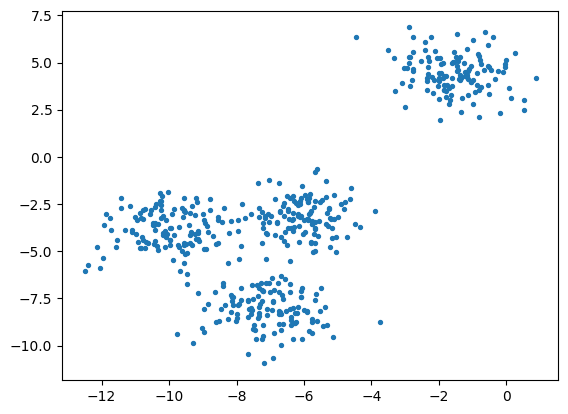

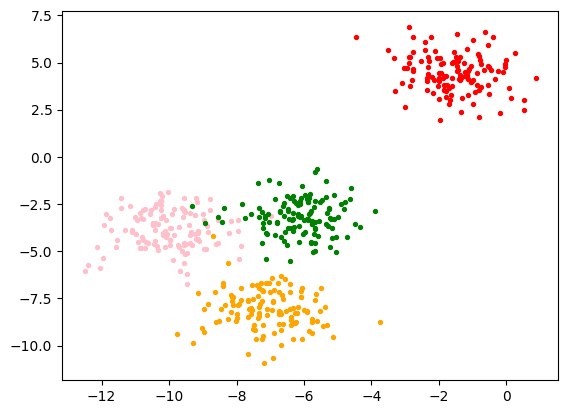

In [52]:
fig, ax1 = plt.subplots(1)
ax1.scatter(X[:, 0], X[:, 1]
            ,marker='o'
            ,s=8
           )
plt.show()

#Color
color = ["red","pink","orange","green"]
fig, ax1 = plt.subplots(1)

for i in range(4):
    ax1.scatter(X[y==i, 0], X[y==i, 1]
                ,marker='o'
                ,s=8
                ,c=color[i]
               )
plt.show()

## Step 4: K-means clustering with 3 clusters
Group the data into three clusters, then view each point's cluster label and the centre of each cluster.

In [55]:
n_clusters = 3
cluster1 = KMeans(n_clusters=n_clusters, random_state=3).fit(X)


In [58]:
#labels
y_pred1 = cluster1.labels_
print(y_pred1)

[2 2 1 0 1 0 1 1 1 1 2 2 1 0 1 2 1 2 0 1 1 1 1 0 1 1 0 0 1 1 2 0 1 2 1 2 1
 1 2 1 1 1 0 1 1 2 1 1 0 0 0 1 1 1 2 1 1 1 1 1 0 0 1 1 0 1 2 1 1 1 2 1 1 2
 1 1 2 1 1 1 0 0 1 0 0 1 1 0 1 1 0 2 1 1 0 2 2 1 2 0 0 2 0 1 0 1 1 0 0 1 1
 2 0 1 0 1 0 1 0 1 1 2 2 1 1 1 0 2 2 1 0 1 1 1 1 2 0 1 0 0 1 2 1 0 0 0 1 1
 2 2 1 1 0 2 0 1 1 1 1 1 1 1 1 1 0 2 2 2 1 0 2 1 1 2 0 1 1 1 1 2 1 1 0 2 2
 1 1 2 2 1 0 0 2 2 1 0 1 2 2 0 2 1 0 1 1 2 1 1 2 1 1 1 1 2 1 1 1 0 1 0 1 2
 1 1 1 1 1 0 1 0 2 1 2 1 0 0 1 2 0 2 1 1 2 2 2 2 1 1 2 1 1 0 0 1 1 0 1 1 1
 0 1 0 1 1 0 1 2 2 1 1 1 1 0 0 1 0 1 2 0 2 0 2 2 0 2 0 0 1 1 1 1 1 1 1 2 0
 2 2 2 1 1 1 2 1 2 2 1 2 2 1 0 2 1 1 0 0 1 2 0 0 1 2 0 0 1 1 0 1 1 2 2 0 1
 2 1 0 0 1 1 1 2 1 0 0 1 0 0 0 0 2 2 1 0 1 1 2 0 1 0 1 0 1 1 1 0 1 1 2 0 2
 2 2 2 2 2 1 2 0 2 0 0 1 0 1 1 1 2 0 1 0 1 2 1 1 2 1 1 0 0 2 1 1 0 1 1 2 2
 1 2 1 1 2 1 2 1 0 2 0 1 1 0 1 1 0 2 1 0 0 1 1 1 1 2 0 2 1 0 2 2 2 1 0 1 2
 1 1 1 1 2 1 1 1 1 1 1 2 1 1 2 1 0 1 0 1 1 1 0 0 0 1 1 1 2 1 0 1 2 0 2 0 2
 1 0 0 2 1 1 2 1 1 1 2 1 

In [60]:
#centroids
centroid1 = cluster1.cluster_centers_
print(centroid1)

[[-1.54234022  4.43517599]
 [-8.0862351  -3.5179868 ]
 [-7.09306648 -8.10994454]]


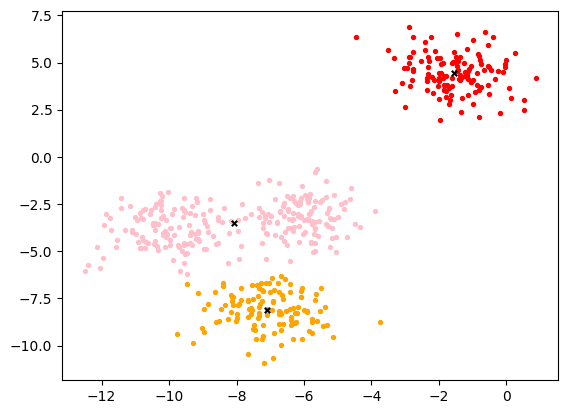

In [61]:
#visualize
color = ["red","pink","orange","gray"]

fig, ax1 = plt.subplots(1)

for i in range(n_clusters):
    ax1.scatter(X[y_pred1==i, 0], X[y_pred1==i, 1]
                ,marker='o'
                ,s=8
                ,c=color[i]
               )

ax1.scatter(centroid1[:,0], centroid1[:,1]
            ,marker="x"
            ,s=15
            ,c="black")
plt.show()

## Step 5: K-means clustering with 4 clusters
Repeat the clustering with 4 clusters, matching the number of groups in the original data.

In [63]:
#Code (fit and centroids):
n_clusters = 4
cluster2 = KMeans(n_clusters=n_clusters, random_state=0).fit(X)
y_pred2 = cluster2.labels_
centroid2 = cluster2.cluster_centers_
print("Centroid: {}".format(centroid2))

Centroid: [[ -6.08459039  -3.17305983]
 [-10.00969056  -3.84944007]
 [ -7.09306648  -8.10994454]
 [ -1.54234022   4.43517599]]


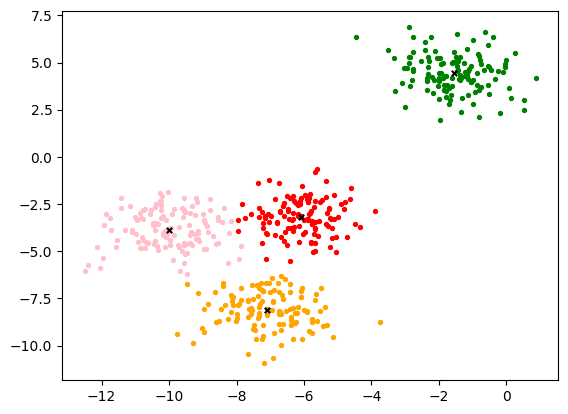

In [65]:
#Code (visualize, in a new cell):
color = ["red","pink","orange","green"]

fig, ax1 = plt.subplots(1)

for i in range(n_clusters):
    ax1.scatter(X[y_pred2==i, 0], X[y_pred2==i, 1]
                ,marker='o'
                ,s=8
                ,c=color[i]
               )

ax1.scatter(centroid2[:,0], centroid2[:,1]
            ,marker="x"
            ,s=15
            ,c="black")
plt.show()

# 1.3 Question: K-means from scratch

**Question:** How to implement K-means from scratch using Python?

**Answer:** K-means can be built with numpy alone by repeating two steps until the clusters stop changing:

1. Pick k random data points as the starting centres.
2. Assignment step: give every point to its nearest centre, using the squared distance to each centre.
3. Update step: move each centre to the mean of the points assigned to it.
4. Repeat steps 2 and 3 until the centres no longer move (or until a maximum number of iterations is reached).

The code below implements this in a function. Run on the same dataset with k = 4, it finds centroids very close to the ones from scikit-learn's KMeans (the order of the centroids may differ).

In [66]:
def kmeans(X, k, iters=100, seed=0):
    rng = np.random.default_rng(seed)
    centers = X[rng.choice(len(X), k, replace=False)]
    for _ in range(iters):
        labels = np.argmin(((X[:, None] - centers[None]) ** 2).sum(axis=2), axis=1)
        new = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centers[j] for j in range(k)])
        if np.allclose(new, centers):
            break
        centers = new
    return labels, centers

labels, centers = kmeans(X, 4)
print(centers)

[[-10.00969056  -3.84944007]
 [ -1.54234022   4.43517599]
 [ -6.08459039  -3.17305983]
 [ -7.09306648  -8.10994454]]
